In [1]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Setup and load

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

base_dir = Path("/content/drive/MyDrive/gdsc-drug-response")
data_path = base_dir / "processed" / "cisplatin_rnaseq_modelready_clean.csv"
df = pd.read_csv(data_path)

df.shape
df.head()

,model_id,drug_name,ln_ic50,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
0,SIDM01132,Cisplatin,3.168266,5.18545,2.9833,0.0000,0.52325,0.0000,0.0213,0.0,...,6.17065,0.31285,1.60475,3.10825,0.6801,0.0,2.58955,5.95435,3.47415,4.0301
1,SIDM00848,Cisplatin,-0.007561,4.86890,3.4476,0.0000,1.99640,0.1243,3.1890,0.0,...,7.09150,1.68260,2.33060,5.18630,0.0841,0.0,3.09930,5.52420,3.60640,4.5211
2,SIDM00269,Cisplatin,0.045420,4.54970,3.8001,0.0841,3.21570,0.0566,0.5753,0.0,...,4.53920,2.82980,3.41280,6.78270,2.3190,0.0,4.21410,9.01050,4.93400,5.4561
3,SIDM00203,Cisplatin,0.923136,4.22500,3.2095,0.0144,0.50590,0.0976,2.8156,0.0,...,6.45100,2.49570,3.47640,5.30710,3.0321,0.0,4.47310,6.95290,4.35900,5.3366
4,SIDM01111,Cisplatin,-0.134330,4.49250,2.8115,0.0144,0.47510,0.0286,0.5558,0.0,...,7.37920,1.28690,2.26000,4.94810,2.7634,0.0,3.20950,3.99550,4.02240,4.9635


In [3]:
# Define columns:

model_col    = "model_id"
drug_col     = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col]
feature_cols = [c for c in df.columns if c not in non_feature_cols]

X = df[feature_cols].values
y = df[response_col].values

X.shape, y.shape

((743, 36438), (743,))

In [4]:
#  Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape

((594, 36438), (149, 36438))

Ridge: Alpha 1.0

In [5]:
# Pipeline: StandardScaler + Ridge

ridge = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    Ridge(alpha=1.0, random_state=42)
)

ridge.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('standardscaler', StandardScaler()),
                ('ridge', Ridge(random_state=42))])

In [6]:
# Predictions:

y_train_pred = ridge.predict(X_train)
y_test_pred  = ridge.predict(X_test)

In [7]:
# Metrics (R², RMSE, MAE) to get different views of performance.

def regression_metrics(y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

r2_train, rmse_train, mae_train = regression_metrics(y_train, y_train_pred)
r2_test,  rmse_test,  mae_test  = regression_metrics(y_test, y_test_pred)

print("Train: R2={:.3f}, RMSE={:.3f}, MAE={:.3f}".format(r2_train, rmse_train, mae_train))
print("Test : R2={:.3f}, RMSE={:.3f}, MAE={:.3f}".format(r2_test,  rmse_test,  mae_test))

Train: R2=1.000, RMSE=0.000, MAE=0.000
Test : R2=0.317, RMSE=1.556, MAE=1.232


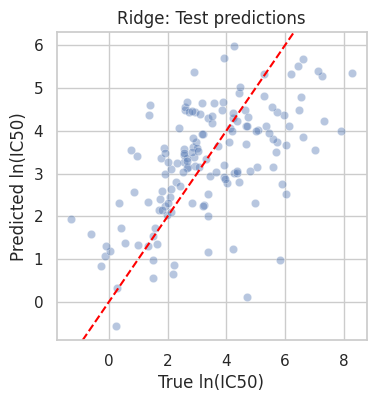

In [8]:
# Predicted vs true (test set):

plt.figure(figsize=(4,4))
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.4)
plt.xlabel("True ln(IC50)")
plt.ylabel("Predicted ln(IC50)")
plt.axline((0,0), slope=1, color="red", linestyle="--")
plt.title("Ridge: Test predictions")
plt.show()

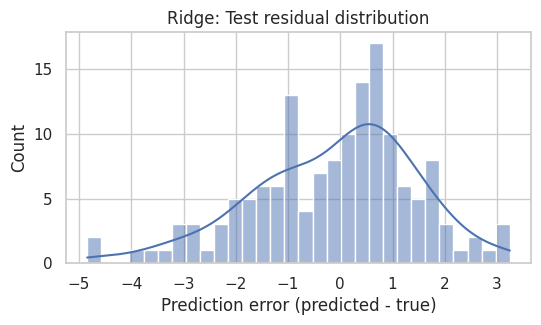

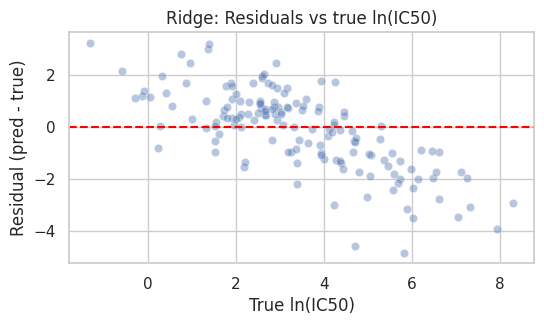

In [9]:
# Residuals (test set) to see error structure:

residuals = y_test_pred - y_test

plt.figure(figsize=(6,3))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel("Prediction error (predicted - true)")
plt.title("Ridge: Test residual distribution")
plt.show()

plt.figure(figsize=(6,3))
sns.scatterplot(x=y_test, y=residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("True ln(IC50)")
plt.ylabel("Residual (pred - true)")
plt.title("Ridge: Residuals vs true ln(IC50)")
plt.show()

In [10]:
# Get the fitted Ridge model and map coefficients back to gene names:

# Grab the underlying Ridge model out of the pipeline
scaler, ridge_model = ridge.named_steps["standardscaler"], ridge.named_steps["ridge"]

coef = ridge_model.coef_  # shape: (n_features,)
len(coef), len(feature_cols)

(36438, 36438)

In [11]:
# Create a dataframe of gene coefficients:

coef_df = pd.DataFrame({
    "gene": feature_cols,
    "coef": coef
})

coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df.sort_values("abs_coef", ascending=False).head(10)

,gene,coef,abs_coef
25140,RN7SKP147,0.014177,0.014177
30032,SLFN11,-0.011923,0.011923
26356,RNU1-6P,-0.009852,0.009852
30789,SPATA2P1,0.008837,0.008837
8472,FAM90A6P,0.008823,0.008823
13758,KRTAP5-11,-0.008151,0.008151
21051,OR5AL1,0.007880,0.007880
18109,MRPL2P1,-0.007658,0.007658
4117,CDY2B,-0.007231,0.007231
10369,GSTT4,-0.007102,0.007102


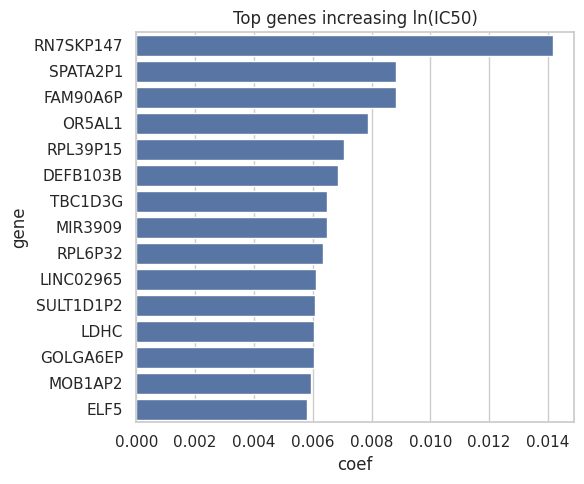

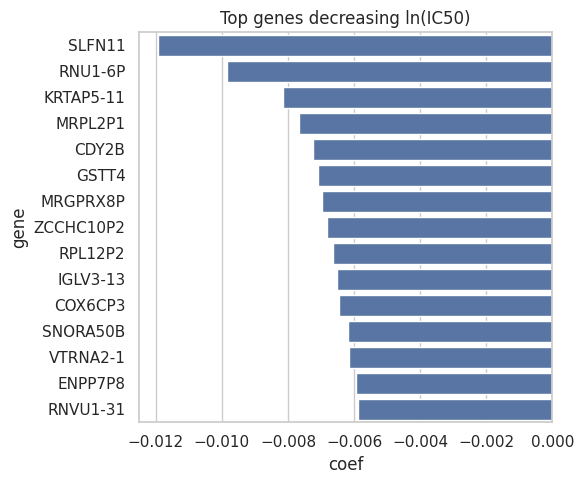

In [12]:
# Plot top positive/negative:

top_pos = coef_df.sort_values("coef", ascending=False).head(15)
top_neg = coef_df.sort_values("coef", ascending=True).head(15)

plt.figure(figsize=(6,5))
sns.barplot(data=top_pos, x="coef", y="gene")
plt.title("Top genes increasing ln(IC50)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
sns.barplot(data=top_neg, x="coef", y="gene")
plt.title("Top genes decreasing ln(IC50)")
plt.tight_layout()
plt.show()

Random Forest

In [13]:
rf = make_pipeline(
    SimpleImputer(strategy="mean"),
    RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        max_features=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
)

rf.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=10, max_features=200,
                                       min_samples_leaf=5, n_jobs=-1,
                                       random_state=42))])

In [14]:
y_train_pred_rf = rf.predict(X_train)
y_test_pred_rf  = rf.predict(X_test)

r2_tr_rf, rmse_tr_rf, mae_tr_rf = regression_metrics(y_train, y_train_pred_rf)
r2_te_rf, rmse_te_rf, mae_te_rf = regression_metrics(y_test,  y_test_pred_rf)

print("Ridge: Train R2={:.3f}, Test R2={:.3f}".format(r2_train, r2_test))
print("RF   : Train R2={:.3f}, Test R2={:.3f}".format(r2_tr_rf, r2_te_rf))

Ridge: Train R2=1.000, Test R2=0.317
RF   : Train R2=0.819, Test R2=0.277


Ridge : Cross Validation to Pick Alpha (10000)

In [15]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]

ridge_cv = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=5)   # 5-fold CV on training set
)

ridge_cv.fit(X_train, y_train)

# Best alpha
best_alpha = ridge_cv.named_steps["ridgecv"].alpha_
print("Best alpha:", best_alpha)

Best alpha: 10000.0


In [16]:
y_train_pred = ridge_cv.predict(X_train)
y_test_pred  = ridge_cv.predict(X_test)

r2_train, rmse_train, mae_train = regression_metrics(y_train, y_train_pred)
r2_test,  rmse_test,  mae_test  = regression_metrics(y_test,  y_test_pred)

print("Train: R2={:.3f}, RMSE={:.3f}, MAE={:.3f}".format(r2_train, rmse_train, mae_train))
print("Test : R2={:.3f}, RMSE={:.3f}, MAE={:.3f}".format(r2_test,  rmse_test,  mae_test))

Train: R2=0.932, RMSE=0.477, MAE=0.353
Test : R2=0.339, RMSE=1.530, MAE=1.223


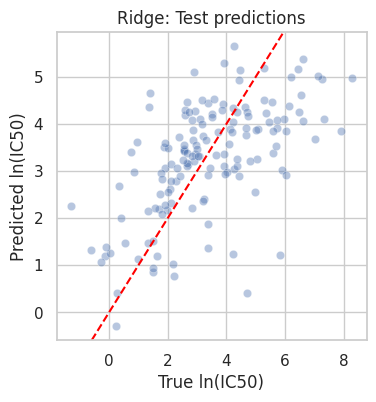

In [17]:
# Predicted vs true (test set):

plt.figure(figsize=(4,4))
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.4)
plt.xlabel("True ln(IC50)")
plt.ylabel("Predicted ln(IC50)")
plt.axline((0,0), slope=1, color="red", linestyle="--")
plt.title("Ridge: Test predictions")
plt.show()

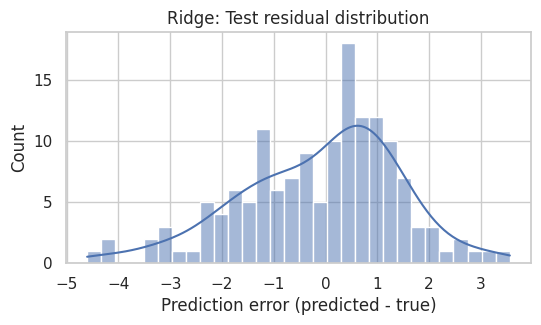

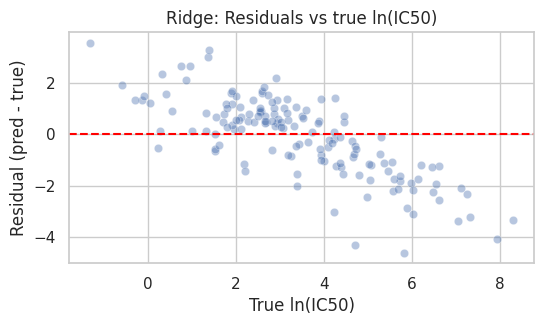

In [18]:
# Residuals (test set) to see error structure:

residuals = y_test_pred - y_test

plt.figure(figsize=(6,3))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel("Prediction error (predicted - true)")
plt.title("Ridge: Test residual distribution")
plt.show()

plt.figure(figsize=(6,3))
sns.scatterplot(x=y_test, y=residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("True ln(IC50)")
plt.ylabel("Residual (pred - true)")
plt.title("Ridge: Residuals vs true ln(IC50)")
plt.show()

Random Forest 2

In [19]:
rf2 = make_pipeline(
    SimpleImputer(strategy="mean"),
    RandomForestRegressor(
        n_estimators=300,     # Increased trees
        max_depth=10,
        max_features=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
)

rf2.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=10, max_features=200,
                                       min_samples_leaf=5, n_estimators=300,
                                       n_jobs=-1, random_state=42))])

In [20]:
y_train_pred_rf2 = rf2.predict(X_train)
y_test_pred_rf2  = rf2.predict(X_test)

r2_tr_rf2, rmse_tr_rf2, mae_tr_rf2 = regression_metrics(y_train, y_train_pred_rf2)
r2_te_rf2, rmse_te_rf2, mae_te_rf2 = regression_metrics(y_test,  y_test_pred_rf2)

print("RF   : Train R2={:.3f}, Test R2={:.3f}".format(r2_tr_rf, r2_te_rf))
print("RF2   : Train R2={:.3f}, Test R2={:.3f}".format(r2_tr_rf2, r2_te_rf2))

RF   : Train R2=0.819, Test R2=0.277
RF2   : Train R2=0.824, Test R2=0.282


Random Forest 3

In [21]:
rf3 = make_pipeline(
    SimpleImputer(strategy="mean"),
    RandomForestRegressor(
        n_estimators=300,
        max_depth=7,         # Reduced max depth
        max_features=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
)

rf3.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=7, max_features=200,
                                       min_samples_leaf=5, n_estimators=300,
                                       n_jobs=-1, random_state=42))])

In [23]:
y_train_pred_rf3 = rf3.predict(X_train)
y_test_pred_rf3  = rf3.predict(X_test)

r2_tr_rf3, rmse_tr_rf3, mae_tr_rf3 = regression_metrics(y_train, y_train_pred_rf3)
r2_te_rf3, rmse_te_rf3, mae_te_rf3 = regression_metrics(y_test,  y_test_pred_rf3)

print("RF   : Train R2={:.3f}, Test R2={:.3f}".format(r2_tr_rf, r2_te_rf))
print("RF2   : Train R2={:.3f}, Test R2={:.3f}".format(r2_tr_rf2, r2_te_rf2))
print("RF3   : Train R2={:.3f}, Test R2={:.3f}".format(r2_tr_rf3, r2_te_rf3))

print("RF3   : Test RMSE={:.3f}, Test MAE={:.3f}".format(rmse_te_rf3, mae_te_rf3))

RF   : Train R2=0.819, Test R2=0.277
RF2   : Train R2=0.824, Test R2=0.282
RF3   : Train R2=0.763, Test R2=0.279
RF3   : Test RMSE=1.599, Test MAE=1.267
